# BÀI 1: Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô hình.


   Noise    Intercept      Slope          MSE         R2
    0.10       4.0122     2.9881       0.0076     0.9973
    0.50       4.0611     2.9404       0.1903     0.9410
    1.00       4.1221     2.8808       0.7612     0.8095
    2.00       4.2442     2.7617       3.0450     0.5387
    5.00       4.6106     2.4041      19.0312     0.1704
   10.00       5.2211     1.8083      76.1248     0.0313


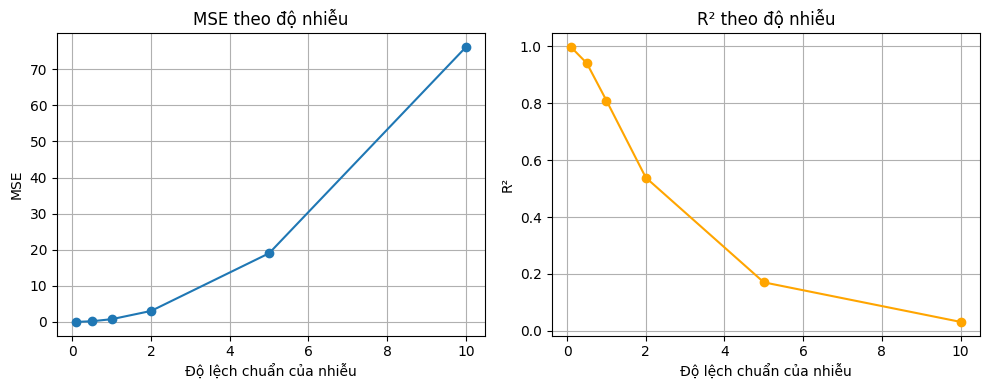

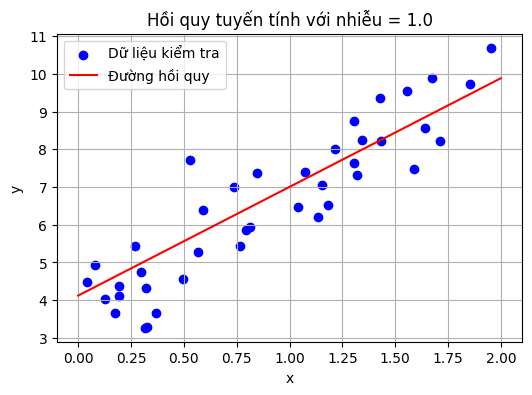

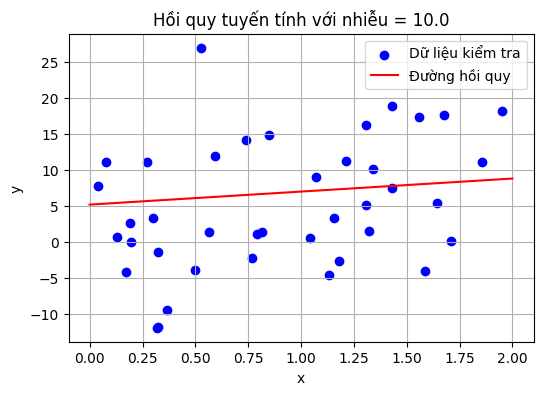

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Cố định seed để kết quả lặp lại được
np.random.seed(0)

n_samples = 200
x = 2 * np.random.rand(n_samples, 1)  # biến đầu vào giả lập

# Các mức độ nhiễu cần khảo sát
noise_levels = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
results = []

for noise in noise_levels:
    # Sinh y = 4 + 3x + nhiễu
    rng = np.random.default_rng(42)
    y = 4 + 3 * x + rng.normal(0, noise, size=(n_samples, 1))

    # Chia dữ liệu huấn luyện / kiểm tra
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    # Huấn luyện mô hình hồi quy tuyến tính
    model = LinearRegression()
    model.fit(x_train, y_train)

    # Dự đoán và đánh giá
    y_pred = model.predict(x_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append((
        noise,
        model.intercept_[0],
        model.coef_[0][0],
        mse,
        r2
    ))

# In bảng kết quả
print(f"{'Noise':>8} {'Intercept':>12} {'Slope':>10} {'MSE':>12} {'R2':>10}")
for noise, intercept, slope, mse, r2 in results:
    print(f"{noise:8.2f} {intercept:12.4f} {slope:10.4f} {mse:12.4f} {r2:10.4f}")

# Vẽ biểu đồ MSE và R2 theo độ nhiễu
noise_arr = np.array([r[0] for r in results])
mse_arr = np.array([r[3] for r in results])
r2_arr = np.array([r[4] for r in results])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(noise_arr, mse_arr, marker='o')
plt.xlabel("Độ lệch chuẩn của nhiễu")
plt.ylabel("MSE")
plt.title("MSE theo độ nhiễu")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(noise_arr, r2_arr, marker='o', color='orange')
plt.xlabel("Độ lệch chuẩn của nhiễu")
plt.ylabel("R²")
plt.title("R² theo độ nhiễu")
plt.grid(True)

plt.tight_layout()
plt.show()

# Minh họa đường hồi quy với nhiễu nhỏ và nhiễu lớn
for noise in [1.0, 10.0]:
    rng = np.random.default_rng(42)
    y = 4 + 3 * x + rng.normal(0, noise, size=(n_samples, 1))

    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(x_train, y_train)

    x_line = np.linspace(0, 2, 100).reshape(-1, 1)
    y_line = model.predict(x_line)

    plt.figure(figsize=(6, 4))
    plt.scatter(x_test, y_test, color='blue', label='Dữ liệu kiểm tra')
    plt.plot(x_line, y_line, color='red', label='Đường hồi quy')
    plt.title(f"Hồi quy tuyến tính với nhiễu = {noise}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.grid(True)
    plt.show()

# Bài 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,… thay vì 0.5) và quan sát sự thay đổi trong kết quả dự đoán.

KẾT QUẢ THEO TỪNG NGƯỠNG

--- Ngưỡng = 0.5 ---
Accuracy : 0.8000
Precision: 0.7952
Recall   : 0.8354
F1-score : 0.8148
Confusion Matrix:
[[54 17]
 [13 66]]
Classification Report:
              precision    recall  f1-score   support

           0      0.806     0.761     0.783        71
           1      0.795     0.835     0.815        79

    accuracy                          0.800       150
   macro avg      0.801     0.798     0.799       150
weighted avg      0.800     0.800     0.800       150


--- Ngưỡng = 0.6 ---
Accuracy : 0.8000
Precision: 0.8182
Recall   : 0.7975
F1-score : 0.8077
Confusion Matrix:
[[57 14]
 [16 63]]
Classification Report:
              precision    recall  f1-score   support

           0      0.781     0.803     0.792        71
           1      0.818     0.797     0.808        79

    accuracy                          0.800       150
   macro avg      0.800     0.800     0.800       150
weighted avg      0.800     0.800     0.800       150


--- Ngưỡng =

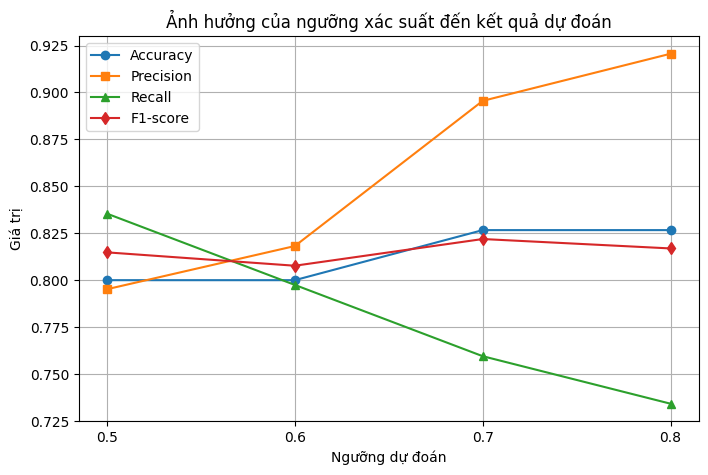

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score
)

# 1. Sinh dữ liệu giả lập BMI -> Mắc bệnh (1: có bệnh, 0: không bệnh)
np.random.seed(42)
n = 500
BMI = np.random.uniform(15, 40, n)

# Xác suất mắc bệnh tăng theo BMI (hàm sigmoid)
p = 1 / (1 + np.exp(-(BMI - 27) / 3))
y = np.random.binomial(1, p)

X = BMI.reshape(-1, 1)

# 2. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Huấn luyện Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Lấy xác suất dự đoán lớp 1
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Thử nhiều ngưỡng
thresholds = [0.5, 0.6, 0.7, 0.8]
accs, precs, recs, f1s = [], [], [], []

print("KẾT QUẢ THEO TỪNG NGƯỠNG\n")

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    accs.append(acc)
    precs.append(prec)
    recs.append(rec)
    f1s.append(f1)

    print(f"--- Ngưỡng = {t} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("Confusion Matrix:")
    print(cm)
    print("Classification Report:")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    print()

# 6. Vẽ biểu đồ so sánh các độ đo theo ngưỡng
plt.figure(figsize=(8, 5))
plt.plot(thresholds, accs, marker='o', label='Accuracy')
plt.plot(thresholds, precs, marker='s', label='Precision')
plt.plot(thresholds, recs, marker='^', label='Recall')
plt.plot(thresholds, f1s, marker='d', label='F1-score')
plt.xlabel("Ngưỡng dự đoán")
plt.ylabel("Giá trị")
plt.title("Ảnh hưởng của ngưỡng xác suất đến kết quả dự đoán")
plt.xticks(thresholds)
plt.grid(True)
plt.legend()
plt.show()

#  Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở

Saving HousingData.csv to HousingData.csv
File đã upload: HousingData.csv
Kích thước ban đầu: (506, 14)

Số lượng NaN theo từng cột:
CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0
dtype: int64

Kích thước sau khi dropna: (394, 14)

===== KẾT QUẢ ĐÁNH GIÁ =====
MSE       : 31.4540
RMSE      : 5.6084 (nghìn USD)
R² score  : 0.6271

Hệ số hồi quy của từng đặc trưng:
Đặc trưng     Hệ số
       RM  2.996655
      RAD  2.069849
       ZN  0.974317
        B  0.894753
     CHAS  0.516120
    INDUS  0.175895
      AGE -0.610267
     CRIM -1.092998
      NOX -1.981255
      TAX -2.074437
  PTRATIO -2.091588
      DIS -2.944644
    LSTAT -2.949953


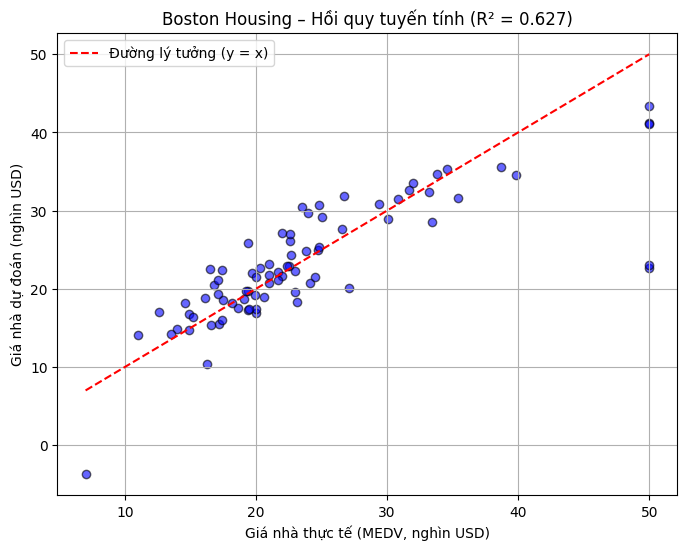

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ==== 1. Upload file từ máy ====
from google.colab import files
uploaded = files.upload()          # Chọn HousingData.csv
filename = list(uploaded.keys())[0]
print("File đã upload:", filename)

# ==== 2. Đọc dữ liệu ====
df = pd.read_csv(filename)
df.columns = [c.strip().upper() for c in df.columns]
print("Kích thước ban đầu:", df.shape)

# ==== 3. KIỂM TRA VÀ XỬ LÝ NaN (đây là bước còn thiếu ở lần chạy trước) ====
print("\nSố lượng NaN theo từng cột:")
print(df.isna().sum())

# Cách A – Loại bỏ các dòng có NaN (đơn giản, phù hợp với dataset nhỏ)
df = df.dropna()
print("\nKích thước sau khi dropna:", df.shape)

# Cách B – Nếu muốn giữ nguyên số mẫu, dùng imputer:
# from sklearn.impute import SimpleImputer
# X = df.drop(columns=["MEDV"]); y = df["MEDV"]
# imp = SimpleImputer(strategy="median")
# X = pd.DataFrame(imp.fit_transform(X), columns=X.columns)

# ==== 4. Tách X, y ====
X = df.drop(columns=["MEDV"])
y = df["MEDV"]

# ==== 5. Chia Train/Test 80–20 ====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==== 6. Chuẩn hóa dữ liệu ====
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# ==== 7. Huấn luyện hồi quy tuyến tính ====
model = LinearRegression()
model.fit(X_train_scaled, y_train)          # ✅ không còn NaN → chạy được

# ==== 8. Dự đoán & đánh giá ====
y_pred = model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

print("\n===== KẾT QUẢ ĐÁNH GIÁ =====")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {np.sqrt(mse):.4f} (nghìn USD)")
print(f"R² score  : {r2:.4f}")

# ==== 9. Hệ số hồi quy ====
coef_df = pd.DataFrame({
    "Đặc trưng": X.columns,
    "Hệ số": model.coef_
}).sort_values(by="Hệ số", ascending=False)
print("\nHệ số hồi quy của từng đặc trưng:")
print(coef_df.to_string(index=False))

# ==== 10. Trực quan hóa ====
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color="blue", edgecolor="k")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", label="Đường lý tưởng (y = x)")
plt.xlabel("Giá nhà thực tế (MEDV, nghìn USD)")
plt.ylabel("Giá nhà dự đoán (nghìn USD)")
plt.title(f"Boston Housing – Hồi quy tuyến tính (R² = {r2:.3f})")
plt.legend()
plt.grid(True)
plt.show()